# SeismicDataset. Подготовка сейсмического датасета #

## 1.4. Расчётная область, поглощение и система наблюдений ##

Как отделить физическое отражение от горизонта от возврата с искусственных границ?

In [1]:
from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from scripts.project_paths import PROJECT_ROOT as ROOT
from scripts.reporting import mapping, number, read_json, sequence

### Что дал демпфирующий слой ###

Сначала сравнили свободные отражающие границы, квадратичное массовое демпфирование и тот же слой с ABC. Сильное гашение у внешнего края может сопровождаться возвратом от входа в слой. Для полосы 175 м подобрали силу по общей L2 скоростей 70 приёмников за 0,5–1 с. Полученный минимум относится к этой норме и этой геометрии; отдельные пики при нём росли.

In [2]:
sweep = read_json((ROOT / "data/dev_1_4_server_preparation/profile_golden_1s_analysis_v1/key_metrics.json"))
print(f"k = {number(sweep['selected_factor']):.4f}, отношение к исходной норме = {number(sweep['ratio_baseline']):.4f}")

k = 0.5684, отношение к исходной норме = 0.6773


Первый вариант в обсуждении обозначался DMP+AMS. В расчётном протоколе записаны две составляющие: в объёме полосы действует вязкая сила с матрицей C = αM, а на внешних боках и дне стоят импедансные условия ABC по нормальной и касательной компонентам. Далее используем обозначения из протокола. В однородной среде легко увидеть оба механизма возврата: волна проходит через пространственно меняющееся демпфирование и достигает внешнего края. Удвоение толщины при растянутом профиле одновременно переносит край и ослабляет гашение у входа.

Поэтому для ядра 700 × 700 м сравнили четыре оформления при одной точечной силе 30 Гц: ABC непосредственно на границе ядра, слой 175 м, слой 350 м с растянутой параболой и слой 350 м с сохранением прежнего профиля на первых 175 м. Последняя пара позволяет сдвинуть внешний край без изменения входной части полосы. Сигнал, изменившийся раньше кинематически возможного возврата от старого края, свидетельствует о влиянии самого профиля. [Протокол четырёх контролей](docs/dev_1_4_damping_layer_protocol_v1.md).

На следующем графике каждая точка — завершённый расчёт или контрольный префикс. Минимизировали позднюю поверхностную норму однородной модели на прямоугольнике 1050 × 875 м. Первые три значения k задали диапазон поиска, затем в нём выполнили девять опытов. Оптимум k = 0,5684 уменьшил целевую норму на 32,3%. При этом у двух из 70 приёмников поздние пики выросли до 2,95%, а до начала целевого окна рост отдельных пиков доходил до 58,7%. Одной настройкой массового демпфирования не удалось одновременно улучшить всю запись.

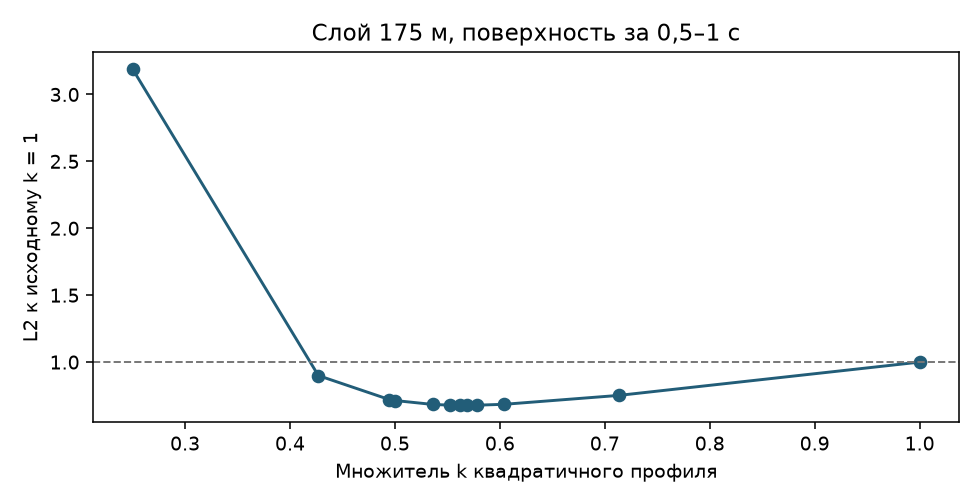

In [3]:
search = read_json(ROOT / "data/dev_1_4_server_preparation/profile_golden_1s_analysis_v1/analysis.json")
points = []
for value in sequence(search["all_evaluations"]):
    evaluation = mapping(value)
    window = mapping(mapping(evaluation["surface_windows"])["0.5_1"])
    points.append((number(evaluation["factor"]), number(window["l2_relative_baseline"])))
points.sort()
fig, axis = plt.subplots(figsize=(7, 3.6))
axis.plot([x for x, _ in points], [y for _, y in points], "o-", color="#225d78")
axis.axhline(1, color="#777777", linestyle="--", linewidth=1)
axis.set(xlabel="Множитель k квадратичного профиля", ylabel="L2 к исходному k = 1", title="Слой 175 м, поверхность за 0,5–1 с")
fig.tight_layout()
fig.savefig(ROOT / "img/dev_1_4_server_preparation/damping_search.png", dpi=140)
plt.close(fig)
display(Image(filename=str(ROOT / "img/dev_1_4_server_preparation/damping_search.png"), width=750))

### От массового демпфирования к PML ###

В направленном декартовом PML поглощение задают раздельно вдоль x и y. В ядре коэффициенты равны нулю, в боковых и нижней полосах они квадратично растут, в углах работают оба направления. Для сравнения с массовым слоем сначала сохранили толщину 175 м. В однородной модели при p4 и p5 поздняя норма ошибки относительно расширенной области уменьшилась примерно в 8,36 раза, а с внешним ABC — в 124 раза. В этом опыте особенно хорошо работало совместное оформление PML и внешней границы. Проверка на слоистой среде поставила другой вопрос: какова остаточная ошибка по сравнению с отражением, которое требуется различить?

Попытка уменьшить число элементов PML при сохранении интеграла гашения привела к росту коэффициента на внешнем краю. При 100 м поверхностные показатели сначала выглядели приемлемо, но после 0,6 с начало расти поле внутри слоя. При толщинах 50 м и меньше наблюдался сильный рост, а уменьшение шага вдвое не устранило его в опыте 10 м. Фиксация максимума 173,09 с⁻¹ подавила этот рост за время наблюдения, но тонкая полоса хуже поглощала волну.

В двухслойной модели усложнили критерий и сравнили ошибку с несколькими PP-приходами. Из проверенных слоёв с ABC ширина 550 м первой дала стократный запас для четырёх окон, даже 1200 м дали лишь 55-кратный запас к пятому. Производственный выбор 350 м относится к другому критерию: разрешить прежде всего первое отражение при доступной стоимости. Для самых слабых кратных волн требуется указывать окно и проверять ошибку отдельно. [Однородный контроль](data/dev_1_5_geometry_frequency/pml_homogeneous_saturn_v1/analysis/metrics.json) · [Толщины слоя](data/dev_1_5_geometry_frequency/pml_thickness_saturn_v1/analysis/metrics.json) · [Несколько PP-окон](data/dev_1_5_geometry_frequency/pml_layered_cached_saturn_v1/analysis/metrics.json).

### Масштаб ошибки на физическом сигнале ###

Размеры ядра и частоту исследовали в 30 опытах: пять прямоугольников, три распределения материала и две частоты (15 и 30 Гц). Двухслойная область 1400×700 м с горизонтом на глубине 350 м дала контроль с известным первым отражением. В сравнении при p4 толстый PML 350 м без ABC уменьшил пик ошибки на поверхности за 0–1 с вне ближайших 20 м в 7,18 раза относительно полосы 100 м с ABC. При собственном более крупном шаге времени сильная прямая волна, напротив, воспроизводилась хуже. Поэтому гашение и точность интегрирования проверяли отдельно.

Для PML за масштаб приняли первое PP-отражение горизонта, выделенное вычитанием однородной модели из слоистой. Ошибку PML определили сравнением с увеличенной областью. Ниже приведён пик по всей линии за 0–1 с для нескольких расстояний источника от начала PML. На проверенной плоской модели пик уже при нулевом расстоянии меньше 1% опорного отражения.

0.0 м: 0.1545%
50.0 м: 0.0913%
100.0 м: 0.0604%
175.0 м: 0.0417%


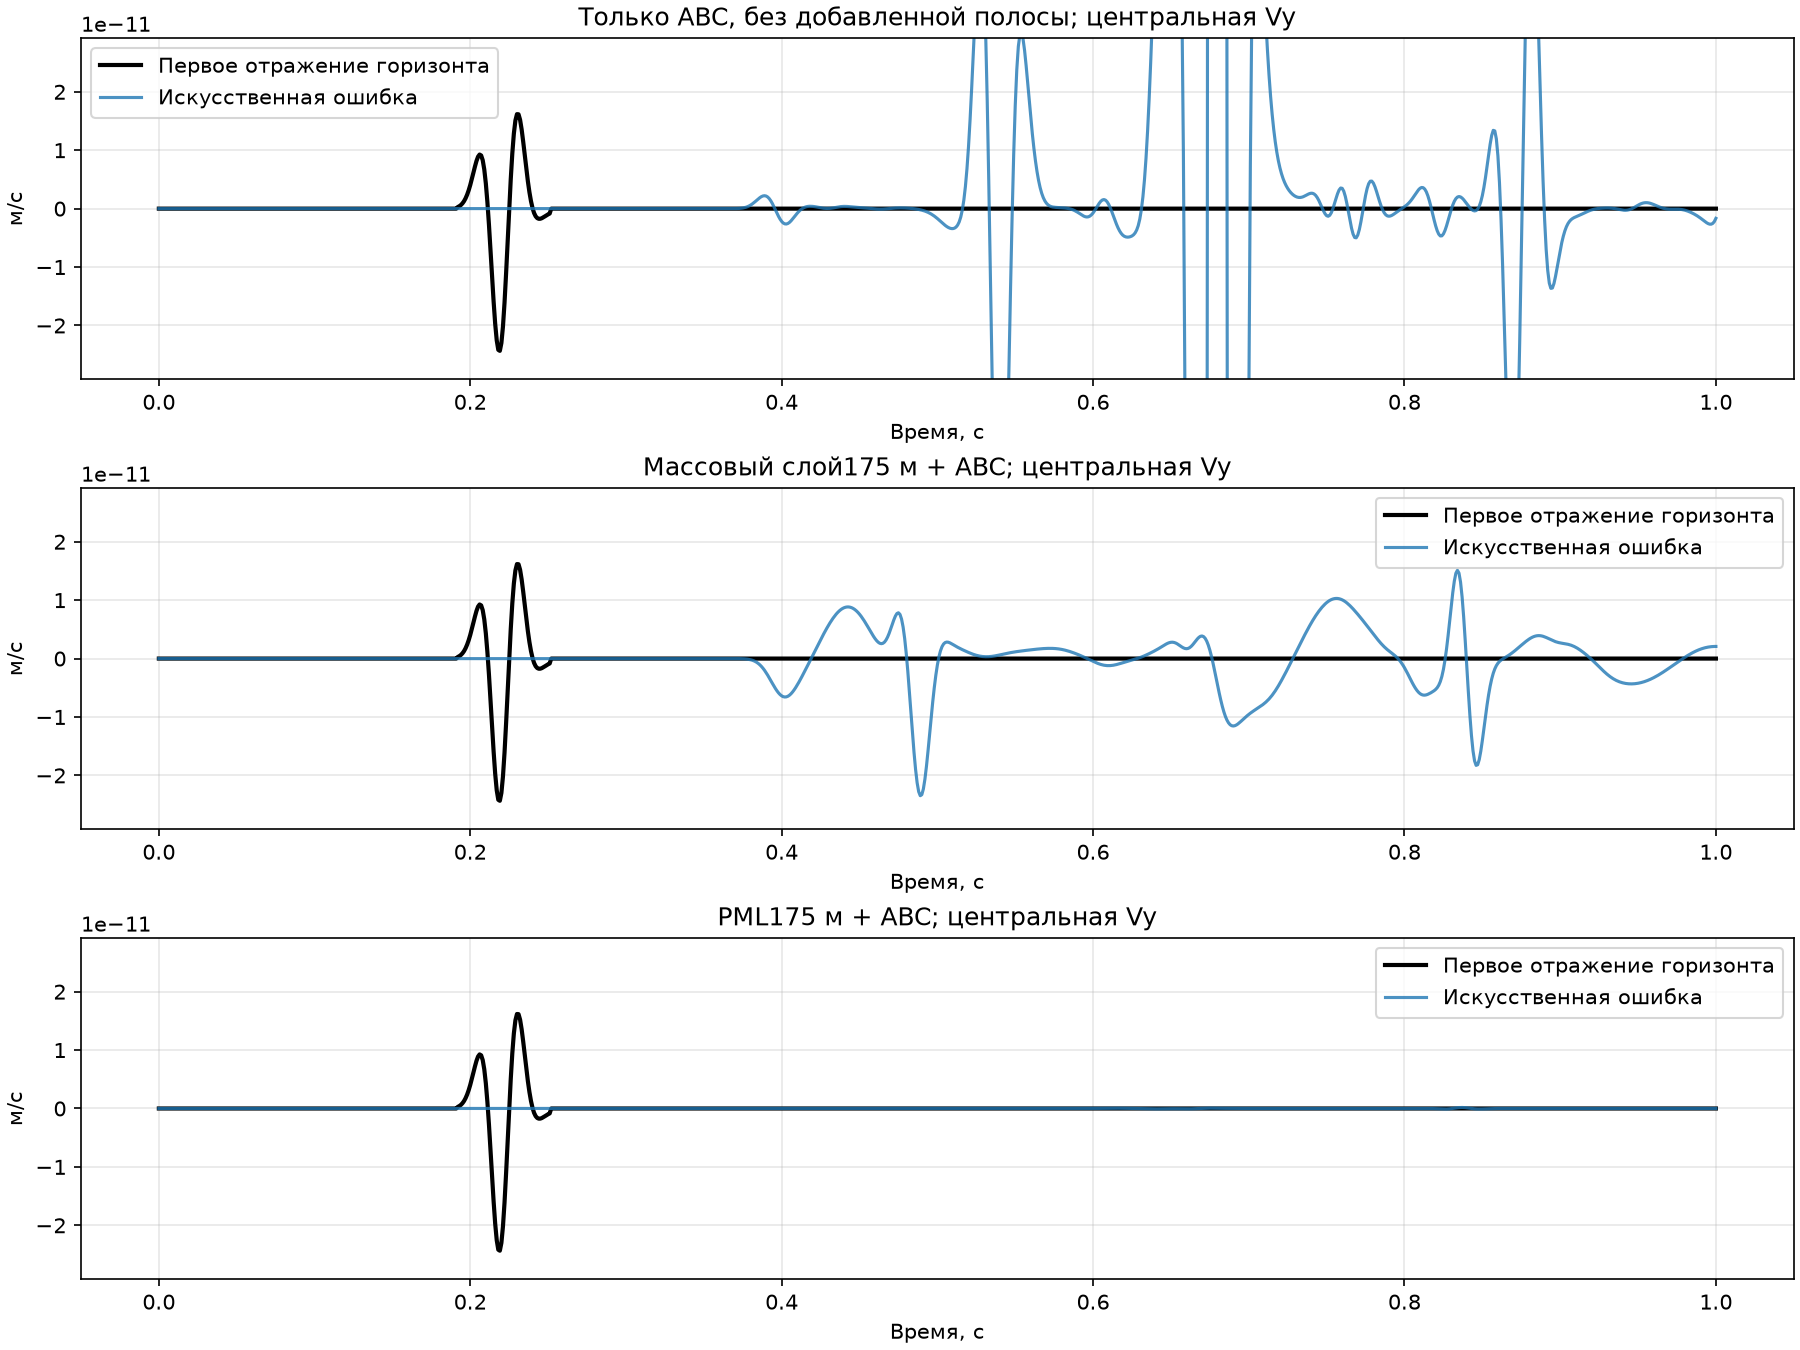

In [4]:
rows = read_json((ROOT / "data/dev_1_6_p67s_showcase/proximity_v1/analysis_v2/analysis.json"))["rows"]
for item in sequence(rows):
    row = mapping(item)
    if row["distance_m"] in (0, 50, 100, 175):
        measures = [mapping(v) for v in sequence(row["metrics"])]
        value = next(m for m in measures if m["window_s"] == [0, 1] and m["receiver_margin_m"] == 0 and not m["exclude_source20"])
        print(f"{row['distance_m']} м: {100*number(value['error_to_horizon_peak']):.4f}%")

display(Image(filename=str(ROOT / "img/dev_1_5_geometry_frequency/pml_first_reflection_v1/central_traces.png"), width=850))

Проверкой записи на поверхности легко пропустить рост внутри поглотителя. График показывает максимум скорости в самом PML в конце расчёта для четырёх вариантов при p4. В варианте 100 м с ABC он растёт к 1 с, тогда как внутри полосы 350 м без ABC затухает. Это наблюдение ограничено длительностью опыта в 1 с.

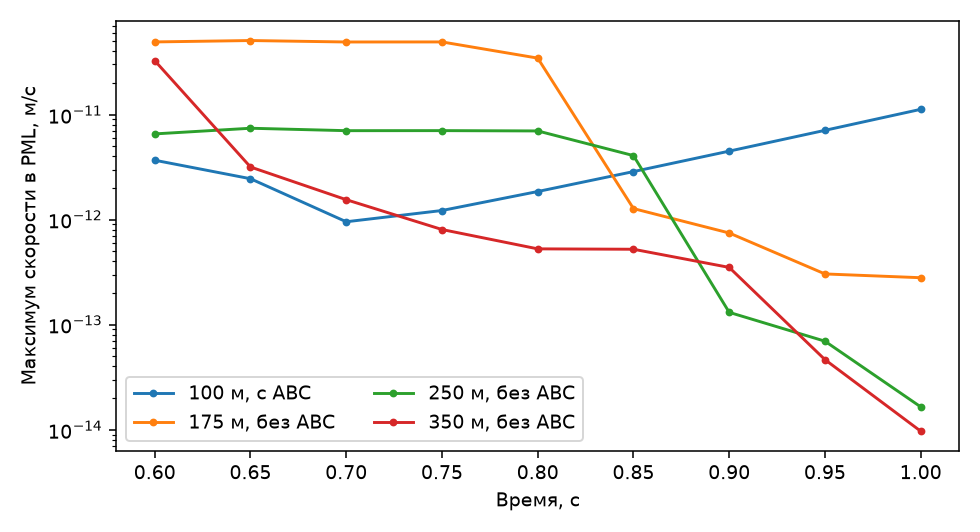

In [5]:
tradeoff = read_json(ROOT / "data/dev_1_5_geometry_frequency/pml_p4_noabc_tradeoff_v1/analysis/metrics.json")
fig, axis = plt.subplots(figsize=(7, 3.8))
for name, row_data in mapping(tradeoff["cases"]).items():
    variant = mapping(row_data)
    times = [number(t) for t in sequence(variant["field_time_s"])]
    peaks = [number(v) for v in sequence(variant["pml_peak_m_s"])]
    window_pairs = [(t, v) for t, v in zip(times, peaks, strict=True) if t >= .6]
    label = f"{variant['thickness_m']} м, " + ("с ABC" if variant["ABC"] else "без ABC")
    axis.semilogy([t for t, _ in window_pairs], [v for _, v in window_pairs], ".-", label=label)
axis.set(xlabel="Время, с", ylabel="Максимум скорости в PML, м/с")
axis.legend(ncol=2)
fig.tight_layout()
fig.savefig(ROOT / "img/dev_1_4_server_preparation/pml_tail.png", dpi=140)
plt.close(fig)
display(Image(filename=str(ROOT / "img/dev_1_4_server_preparation/pml_tail.png"), width=750))

### Постановка для датасета ###

| Параметр | Принятое значение |
|---|---|
| Среда | Плоская деформация, исходные Vp/Vs, ρ=1000 кг/м³ |
| Область | Ядро 1400×700 м, полная область 2100×1050 м |
| Границы | Свободный верх. Слева, справа и снизу декартов PML 350 м, квадратичный профиль до 173,09 с⁻¹ по каждой оси, без дополнительного ABC |
| Источник | Вертикальная сила вниз 1 Н/м, Рикер 30 Гц, максимум в 0,05 с |
| Наблюдения | Vx/Vy на поверхности при x=5,15,…,1395 м, 1001 отсчёт за 1 с |
| Интегрирование | FP64, Newmark–Kim β=1/27, γ=0,5, внутренний шаг по CFL с коэффициентом 0,8 |

В расширенной модели источник при x=100 м отстоит на 100 м от начала левого PML. Глубина физической области остаётся 700 м. Вход в PML сохраняет материал прилегающего элемента.

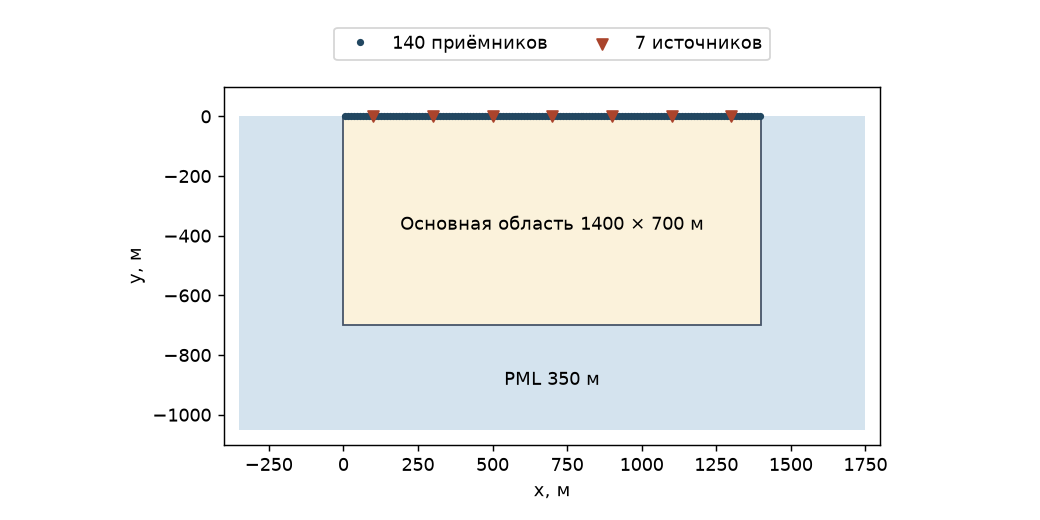

In [6]:
fig, axis = plt.subplots(figsize=(8, 4))
axis.add_patch(Rectangle((-350, -1050), 2100, 1050, facecolor="#d4e3ee"))
axis.add_patch(Rectangle((0, -700), 1400, 700, facecolor="#fbf2db", edgecolor="#475569"))
axis.plot(range(5, 1400, 10), [0]*140, ".", color="#224761", label="140 приёмников")
axis.scatter(range(100, 1400, 200), [0]*7, marker="v", color="#aa442c", label="7 источников", zorder=3)
axis.text(700, -380, "Основная область 1400 × 700 м", ha="center")
axis.text(700, -900, "PML 350 м", ha="center")
axis.set(xlim=(-400, 1800), ylim=(-1100, 100), aspect="equal", xlabel="x, м", ylabel="y, м")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, 1.19), ncol=2)
fig.tight_layout()
fig.savefig(ROOT / "img/dev_1_4_server_preparation/production_domain.png", dpi=130)
plt.close(fig)

display(Image(filename=str(ROOT / "img/dev_1_4_server_preparation/production_domain.png"), width=850))

### Вывод ###

Приняты ядро 1400×700 м, PML350, свободный верх и запись 1 с. Сопоставление ошибки с первым отражением даёт физический масштаб, относительно которого можно оценивать влияние внешней границы.